# DOE-044
## POR トレンド

- 対象銘柄: 9984
- 実験計画: 完全実施要因計画 (Full Factorial Design)
- 実験パラメータ
    - なし
- 固定パラメータ
    - PERIOD_WARMUP: 90
        - インジケータのウォームアップ期間（ティック数）
    - TYPE_MA_1: EMA
    - PERIOD_MA_1: 240
        - 短周期移動平均線
    - PERIOD_MA_2: 2200
        - 長周期移動平均線
    - START_TRAILING: 20
        - トレーリング・ストップを開始する最大含み益
    - THRESHOLD_TRAILING: 0.90
        - トレーリング・ストップのしきい値比
    - FOLLOWING_MIN: 15
        - 順方向に設定回数以上で逆方向カウンタが越えればロスカット
    - LOSSCUT_SIMPLE: float = -50
        - 単純ロスカット（実質的に無効）
- MA1 / MA2 クロス・シグナルのエントリ・エグジット
    - クロス時に反対売買をしない。
- 評価指標
    - 収益と約定回数

In [1]:
from pathlib import Path

import pandas as pd

# === 実験番号 ===
name_doe = "doe-044"

# pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 300)

# 指定したディレクトリのPathオブジェクトを作成
dir_path = Path(f"../../backtest/{name_doe}")
print(dir_path)

# .glob() で .csv ファイルのリスト（イテレータ）を取得してリストに変換
list_csv_file = sorted([str(p) for p in dir_path.glob("*.csv") if p.is_file()])

# 集計対象の条件列
columns_group = [
    "TYPE_MA_1",
    "PERIOD_MA_1",
    "PERIOD_MA_2",
]

# CSV ファイルを読み込んで結合
df = pd.concat(
    [
        pd.read_csv(file).assign(
            DATE=pd.to_datetime(Path(file).stem[:8], format="%Y%m%d")
        )
        for file in list_csv_file
    ],
    ignore_index=True,
)

# 条件ごとに Profit を集計
df_total = df.groupby(columns_group, as_index=False).agg(
    Profit_Total=("Profit", "sum"),
    Profit_Mean=("Profit", "mean"),
    Profit_Median=("Profit", "median"),
    Transactions_Median=("Transactions", "median"),
)

print(df)
print("\nSummary Statistics")
print("\n*** Past", len(list_csv_file), "days statistics ***")
print(df_total)

../../backtest/doe-044
   TYPE_MA_1  PERIOD_MA_1  PERIOD_MA_2  Profit  Transactions       DATE
0        EMA          240         2200   -16.0           8.0 2026-09-01
1        EMA          240         2200   -69.0           8.0 2026-09-02
2        EMA          240         2200    79.0          14.0 2026-09-03
3        EMA          240         2200    97.0           6.0 2026-09-04
4        EMA          240         2200    -3.0           6.0 2026-09-07
5        EMA          240         2200   243.0          16.0 2026-09-08
6        EMA          240         2200  -349.0          22.0 2026-09-09
7        EMA          240         2200     6.0          14.0 2026-09-10
8        EMA          240         2200   -63.0          14.0 2026-09-11
9        EMA          240         2200   157.0          12.0 2026-09-14
10       EMA          240         2200   213.0          10.0 2026-09-15
11       EMA          240         2200   171.0          10.0 2026-09-16
12       EMA          240         2200   

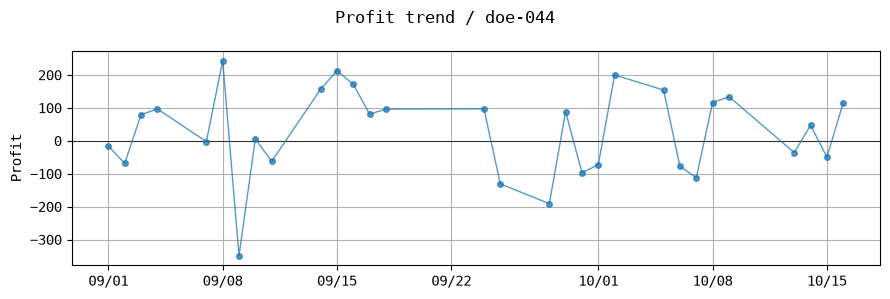

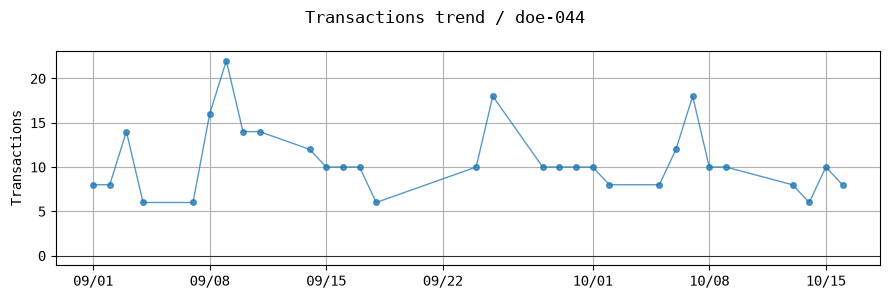

In [3]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "monospace"

for name_y in ["Profit", "Transactions"]:
    fig, ax = plt.subplots(1, 1, figsize=(9, 3))

    # stripplot の x 軸位置（0, 1, 2...）に合わせて線をつなぐ
    x = df["DATE"]
    y = df[name_y]
    ax.plot(
        x,
        y,
        "o-",
        color="C0",
        markersize=4,
        linewidth=1,
        alpha=0.75,
        zorder=5,  # 点の裏に隠れないよう前面に描画
    )
    ax.set(ylabel=name_y)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d'))
    ax.axhline(y=0, color='black', linewidth=0.75, alpha=0.75)
    ax.grid(True)
    
    fig.suptitle(f"{name_y} trend / {name_doe}")
    
    plt.tight_layout()
    pngfile = f"../../backtest/{name_doe}/trend_{name_y}.png"
    plt.savefig(pngfile)
    plt.show()